In [117]:
import pandas as pd 

df = pd.read_csv("../data/raw/spam.csv", encoding = "latin-1")

In [118]:
df = df.rename(columns={"v1": "message_type", "v2": "message"})
extra = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

df["message"] = df[["message"] + extra].apply(
    lambda row: ",".join(row.dropna()), axis = 1
)
df = df.drop(columns=extra)

print(df.shape)
print(df.info())

(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   message_type  5572 non-null   object
 1   message       5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


message_type
ham     0.865937
spam    0.134063
Name: proportion, dtype: float64


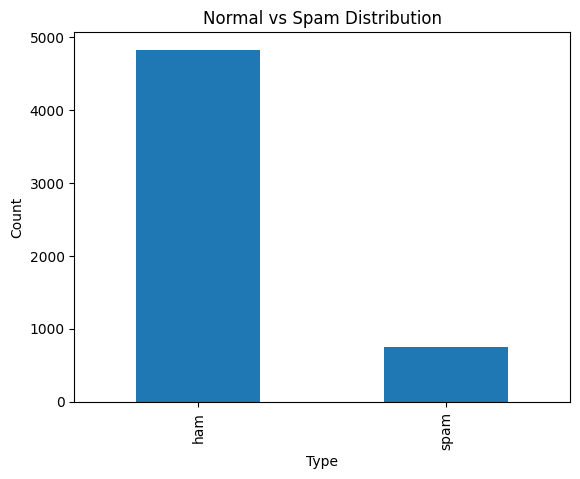

In [119]:
import matplotlib.pyplot as plt
print(df.message_type.value_counts(normalize=True))
df.message_type.value_counts().plot(kind = "bar")
plt.title("Normal vs Spam Distribution")
plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

# Basic Stats of Messages Lengths

In [120]:
df["message_length"] = df.message.apply(len)
print(df["message_length"].describe())

count    5572.000000
mean       80.692211
std        60.007878
min         2.000000
25%        36.000000
50%        62.000000
75%       123.000000
max       910.000000
Name: message_length, dtype: float64


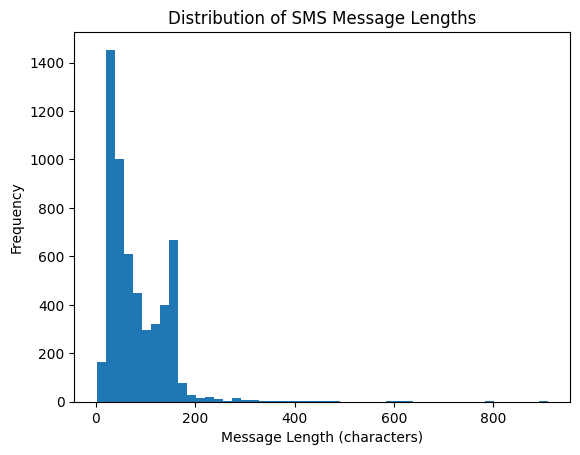

In [121]:
plt.hist(df["message_length"], bins=50)

plt.title("Distribution of SMS Message Lengths")
plt.xlabel("Message Length (characters)")
plt.ylabel("Frequency")

plt.show()

Compare Spam vs Ham

In [122]:
print(df["message_length"].groupby(df["message_type"]).describe())

               count        mean        std   min    25%    50%    75%    max
message_type                                                                 
ham           4825.0   71.640622  58.458559   2.0   33.0   52.0   93.0  910.0
spam           747.0  139.157965  28.981074  13.0  133.0  149.0  158.0  224.0


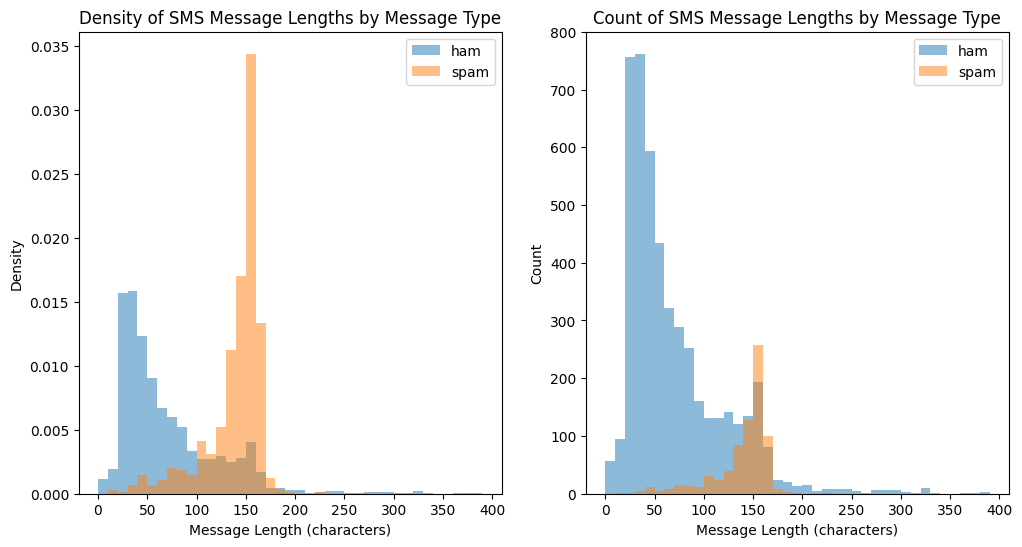

In [123]:
bins = range(0, 400, 10)

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 6))

for label in ["ham", "spam"]:
    axes[0].hist(
        df.loc[df["message_type"] == label, "message_length"],
        bins=bins,
        alpha=0.5,
        density=True,
        label=label
    )
    axes[1].hist(
        df.loc[df["message_type"] == label, "message_length"],
        bins=bins,
        alpha=0.5,
        density=False,
        label=label
    )
axes[0].set_title("Density of SMS Message Lengths by Message Type")
axes[1].set_title("Count of SMS Message Lengths by Message Type")
axes[0].set_xlabel("Message Length (characters)")
axes[1].set_xlabel("Message Length (characters)")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Count")
axes[0].legend()
axes[1].legend()
plt.show()

In [124]:
pd.crosstab(df.message_type, df.message_length > 120)

message_length,False,True
message_type,,
ham,3997,828
spam,134,613


# Basic Statistics of Words Used in SMS Messages    

In [125]:
words = (
    df.assign(word=df.message.str.lower().str.split())
    .explode("word")
)
word_in_ham  = words.loc[words.message_type == "ham",  "word"]
word_in_spam = words.loc[words.message_type == "spam", "word"]

In [126]:
words.head(10)

,message_type,message,message_length,word
0,ham,"Go until jurong point, crazy.. Available only ...",111,go
0,ham,"Go until jurong point, crazy.. Available only ...",111,until
0,ham,"Go until jurong point, crazy.. Available only ...",111,jurong
0,ham,"Go until jurong point, crazy.. Available only ...",111,"point,"
0,ham,"Go until jurong point, crazy.. Available only ...",111,crazy..
0,ham,"Go until jurong point, crazy.. Available only ...",111,available
0,ham,"Go until jurong point, crazy.. Available only ...",111,only
0,ham,"Go until jurong point, crazy.. Available only ...",111,in
0,ham,"Go until jurong point, crazy.. Available only ...",111,bugis
0,ham,"Go until jurong point, crazy.. Available only ...",111,n


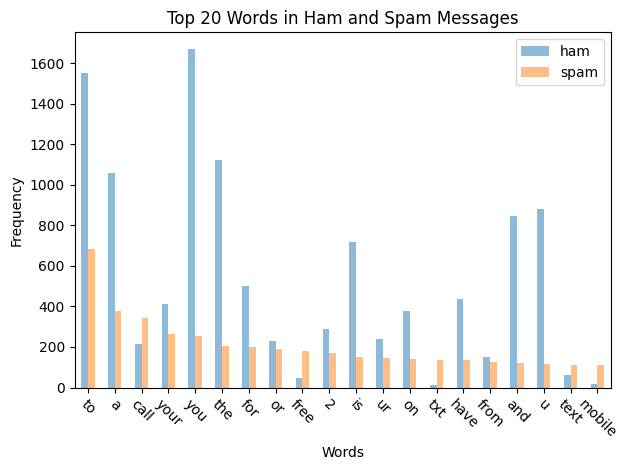

In [127]:
ham_counts = pd.Series(word_in_ham.value_counts())
spam_counts = pd.Series(word_in_spam.value_counts())

spam_total = sum(spam_counts)
ham_total = sum(ham_counts)

word_counts = pd.concat([ham_counts, spam_counts], axis = 1, keys = ["ham", "spam"]).fillna(0)

word_counts["ratio"] = ((word_counts["spam"] + 1) / spam_total) / ((word_counts["ham"] + 1) / ham_total)

top_words = (
    word_counts.sort_values(by = "spam", ascending = False)
    .head(20)
    .drop(columns = "ratio")
)

top_words.plot(kind = "bar", alpha = 0.5, label = "Spam")

plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 20 Words in Ham and Spam Messages")
plt.xticks(rotation=-45)
plt.legend()
plt.tight_layout()
plt.show()

In [128]:
message_word_count = pd.DataFrame(
    pd.Series(word.lower() for word in message.split()).value_counts() 
    for message in df.message 
).fillna(0)